# Lab 05 — Sparse Autoencoder on CIFAR-10

**Aim:** adapt the Sparse Autoencoder from `sae.py` (written for MNIST) to learn compressed representations of CIFAR-10 images.

## 1. Study of `sae.py`

- **Encoder:** `Linear(784 → h_dims)` + `Sigmoid`
- **Decoder:** `Linear(h_dims → 784)` + `Tanh`
- **Reconstruction loss:** MSE between input and output
- **Sparsity penalty:** KL divergence that pushes each hidden neuron's average activation towards a small target (ρ = 0.05), weighted by λ
- **For CIFAR-10:** input changes from 784 to 3072 (32 × 32 × 3)

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(1337)
np.random.seed(1337)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device)

PyTorch 2.14.0+cu130 | device: cuda


## 2. Load and pre-process CIFAR-10

- Convert images to tensors
- Normalize to [−1, 1] (matches the Tanh output)
- Flatten 32 × 32 × 3 → 3072

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),                                   # HWC uint8 -> CHW float in [0,1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # [0,1] -> [-1,1]
    transforms.Lambda(torch.flatten),                        # 3x32x32 -> 3072
])

train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_set = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
CLASSES = train_set.classes

def to_tensors(ds):
    xs, ys = zip(*(ds[i] for i in range(len(ds))))
    return torch.stack(xs), torch.tensor(ys)

X_train, y_train = to_tensors(train_set)
X_test, y_test = to_tensors(test_set)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print(f'Value range: [{X_train.min():.2f}, {X_train.max():.2f}]')
assert X_train.shape[1] == 32 * 32 * 3 == 3072

Train: torch.Size([50000, 3072]) | Test: torch.Size([10000, 3072])
Value range: [-1.00, 1.00]


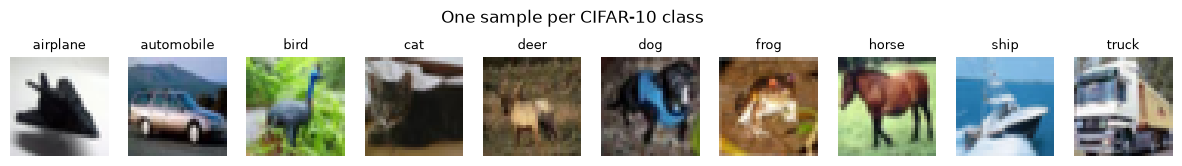

In [3]:
def to_img(v):
    # 3072 vector in [-1,1] -> 32x32x3 image in [0,1] for plotting
    return (v.detach().cpu().view(3, 32, 32).permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1).numpy()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c, ax in enumerate(axes):
    i = (y_train == c).nonzero()[0].item()
    ax.imshow(to_img(X_train[i])); ax.set_title(CLASSES[c], fontsize=9); ax.axis('off')
plt.suptitle('One sample per CIFAR-10 class'); plt.show()

## 3. Adapted Sparse Autoencoder

- `in_dims` = 3072, `h_dims` = 1024
- Structure: 3072 → 1024 (Sigmoid) → 3072 (Tanh)

In [4]:
class SparseAutoencoder(nn.Module):
    def __init__(self, in_dims=3072, h_dims=1024, sparsity_lambda=1e-4, sparsity_target=0.05):
        super().__init__()
        self.sparsity_lambda = sparsity_lambda
        self.sparsity_target = sparsity_target
        self.encoder = nn.Sequential(nn.Linear(in_dims, h_dims), nn.Sigmoid())
        self.decoder = nn.Sequential(nn.Linear(h_dims, in_dims), nn.Tanh())
        for layer in (self.encoder[0], self.decoder[0]):    # Xavier init, as in sae.py
            nn.init.xavier_uniform_(layer.weight)
            nn.init.constant_(layer.bias, 0)

    def forward(self, x):
        encoded = self.encoder(x)
        return encoded, self.decoder(encoded)

    def sparsity_penalty(self, encoded):
        rho = self.sparsity_target
        rho_hat = encoded.mean(dim=0).clamp(1e-8, 1 - 1e-8)   # mean activation of each hidden neuron
        kl = rho * torch.log(rho / rho_hat) + (1 - rho) * torch.log((1 - rho) / (1 - rho_hat))
        return self.sparsity_lambda * kl.sum()

    def loss_function(self, x_hat, x, encoded):
        mse = F.mse_loss(x_hat, x)
        sparse = self.sparsity_penalty(encoded)
        return mse + sparse, mse, sparse

model = SparseAutoencoder()
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

SparseAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=3072, out_features=1024, bias=True)
    (1): Sigmoid()
  )
  (decoder): Sequential(
    (0): Linear(in_features=1024, out_features=3072, bias=True)
    (1): Tanh()
  )
)
Trainable parameters: 6295552


## 4. Training

Batch size 128, learning rate 1e-3 (Adam), 25 epochs, ρ = 0.05, λ = 1e-4.

In [5]:
X_train_d, X_test_d = X_train.to(device), X_test.to(device)

@torch.no_grad()
def evaluate(model, X, batch_size=1000):
    # Returns mean test MSE, mean sparsity term and all hidden activations
    model.eval()
    mse, sparse, codes = 0.0, 0.0, []
    for i in range(0, len(X), batch_size):
        x = X[i:i + batch_size]
        enc, dec = model(x)
        _, m, s = model.loss_function(dec, x, enc)
        mse += m.item() * len(x); sparse += s.item() * len(x); codes.append(enc)
    return mse / len(X), sparse / len(X), torch.cat(codes)

def train_model(model, n_epochs=25, lr=1e-3, batch_size=128, verbose=True):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_d), batch_size=batch_size, shuffle=True)
    hist = {'train_mse': [], 'test_mse': []}
    for epoch in range(n_epochs):
        model.train()
        total_mse = 0.0
        for (x,) in loader:
            enc, dec = model(x)
            loss, mse, _ = model.loss_function(dec, x, enc)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            total_mse += mse.item()
        test_mse, test_sparse, _ = evaluate(model, X_test_d)
        hist['train_mse'].append(total_mse / len(loader)); hist['test_mse'].append(test_mse)
        if verbose and (epoch % 5 == 4 or epoch == 0):
            print(f'Epoch {epoch+1:2d}/{n_epochs} | train MSE {hist["train_mse"][-1]:.4f} '
                  f'| test MSE {test_mse:.4f} | sparsity term {test_sparse:.4f}')
    return hist

torch.manual_seed(1337)
model = SparseAutoencoder(sparsity_lambda=1e-4)
t0 = time.time()
hist = train_model(model)
print(f'Training time: {time.time() - t0:.1f}s')

Epoch  1/25 | train MSE 0.0555 | test MSE 0.0307 | sparsity term 0.0236


Epoch  5/25 | train MSE 0.0150 | test MSE 0.0153 | sparsity term 0.0108


Epoch 10/25 | train MSE 0.0113 | test MSE 0.0120 | sparsity term 0.0045


Epoch 15/25 | train MSE 0.0103 | test MSE 0.0110 | sparsity term 0.0024


Epoch 20/25 | train MSE 0.0095 | test MSE 0.0103 | sparsity term 0.0015


Epoch 25/25 | train MSE 0.0087 | test MSE 0.0101 | sparsity term 0.0011
Training time: 64.4s


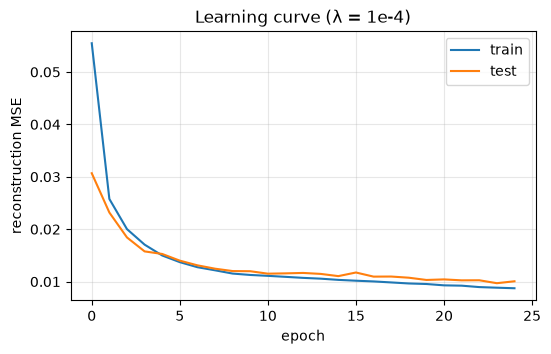

In [6]:
plt.figure(figsize=(6, 3.5))
plt.plot(hist['train_mse'], label='train')
plt.plot(hist['test_mse'], label='test')
plt.xlabel('epoch'); plt.ylabel('reconstruction MSE'); plt.title('Learning curve (λ = 1e-4)')
plt.legend(); plt.grid(alpha=.3); plt.show()

## 5. Test-set reconstruction loss

In [7]:
test_mse, test_sparse, codes = evaluate(model, X_test_d)
psnr = lambda mse: 10 * np.log10(1 / (mse / 4))
print(f'Test reconstruction MSE : {test_mse:.4f}')
print(f'Test PSNR               : {psnr(test_mse):.2f} dB')
print(f'Sparsity penalty term   : {test_sparse:.4f}')
print(f'Mean hidden activation  : {codes.mean():.3f}  (target ρ = 0.05)')

Test reconstruction MSE : 0.0101
Test PSNR               : 25.99 dB
Sparsity penalty term   : 0.0011
Mean hidden activation  : 0.086  (target ρ = 0.05)


## 6. Original vs reconstructed images

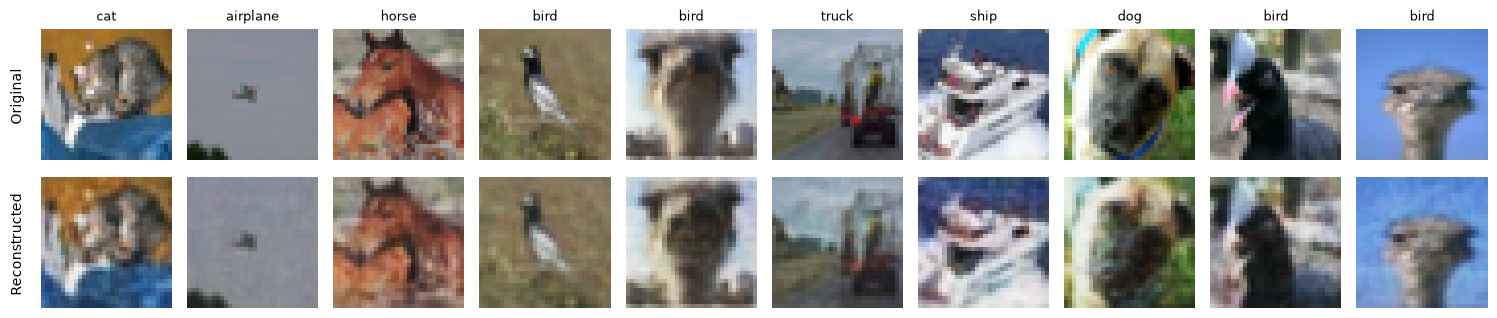

In [8]:
idx = torch.arange(10) * 97   # fixed, varied picks from the test set
with torch.no_grad():
    _, recon = model(X_test_d[idx])

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for k, i in enumerate(idx):
    axes[0, k].imshow(to_img(X_test[i])); axes[0, k].set_title(CLASSES[y_test[i]], fontsize=9)
    axes[1, k].imshow(to_img(recon[k]))
for ax in axes.flat: ax.axis('off')
axes[0, 0].text(-8, 16, 'Original', rotation=90, va='center')
axes[1, 0].text(-8, 16, 'Reconstructed', rotation=90, va='center')
plt.tight_layout(); plt.show()

### Hidden activations

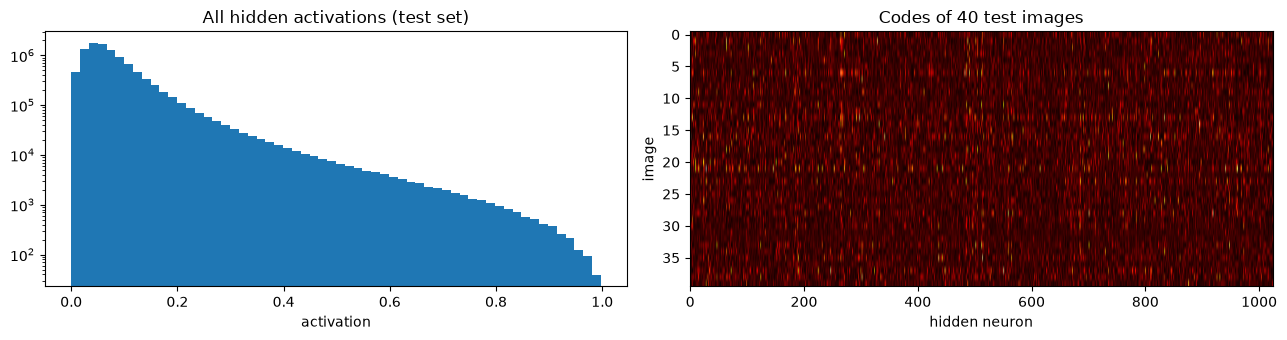

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(codes.flatten().cpu().numpy(), bins=60)
axes[0].set_title('All hidden activations (test set)'); axes[0].set_xlabel('activation'); axes[0].set_yscale('log')
axes[1].imshow(codes[:40].cpu().numpy(), aspect='auto', cmap='hot')
axes[1].set_title('Codes of 40 test images'); axes[1].set_xlabel('hidden neuron'); axes[1].set_ylabel('image')
plt.tight_layout(); plt.show()

## 7. Effect of sparsity (λ)

Same model trained with λ = 0, 1e-5, 1e-4, 1e-3, 1e-2 (15 epochs each).

In [10]:
lambdas = [0, 1e-5, 1e-4, 1e-3, 1e-2]
results, sweep_models = [], {}
for lam in lambdas:
    torch.manual_seed(1337)
    m = SparseAutoencoder(sparsity_lambda=lam)
    train_model(m, n_epochs=15, verbose=False)
    mse, _, c = evaluate(m, X_test_d)
    rho_hat = c.mean(0)
    results.append(dict(lam=lam, mse=mse, psnr=psnr(mse), mean_act=c.mean().item(),
                        active=(c > 0.1).float().mean().item() * 100, dead=(rho_hat < 1e-3).sum().item()))
    sweep_models[lam] = m
    r = results[-1]
    print(f"λ={lam:<7g} test MSE {r['mse']:.4f} | PSNR {r['psnr']:.2f} dB | mean act {r['mean_act']:.3f} "
          f"| active {r['active']:5.1f}% | dead {r['dead']}")

λ=0       test MSE 0.0086 | PSNR 26.66 dB | mean act 0.457 | active  98.4% | dead 0


λ=1e-05   test MSE 0.0085 | PSNR 26.74 dB | mean act 0.332 | active  94.3% | dead 0


λ=0.0001  test MSE 0.0110 | PSNR 25.59 dB | mean act 0.108 | active  38.2% | dead 0


λ=0.001   test MSE 0.0149 | PSNR 24.28 dB | mean act 0.061 | active  15.5% | dead 0


λ=0.01    test MSE 0.0244 | PSNR 22.15 dB | mean act 0.055 | active  12.3% | dead 0


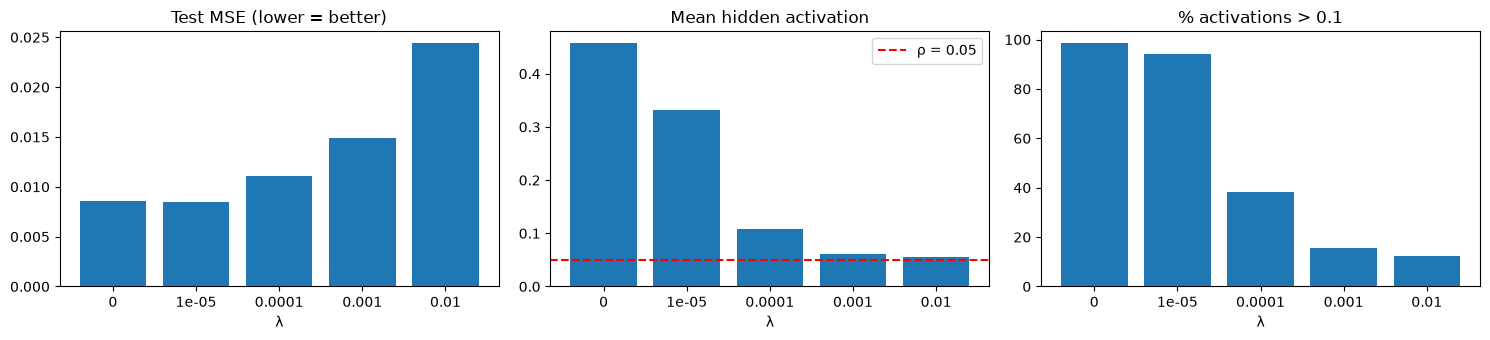

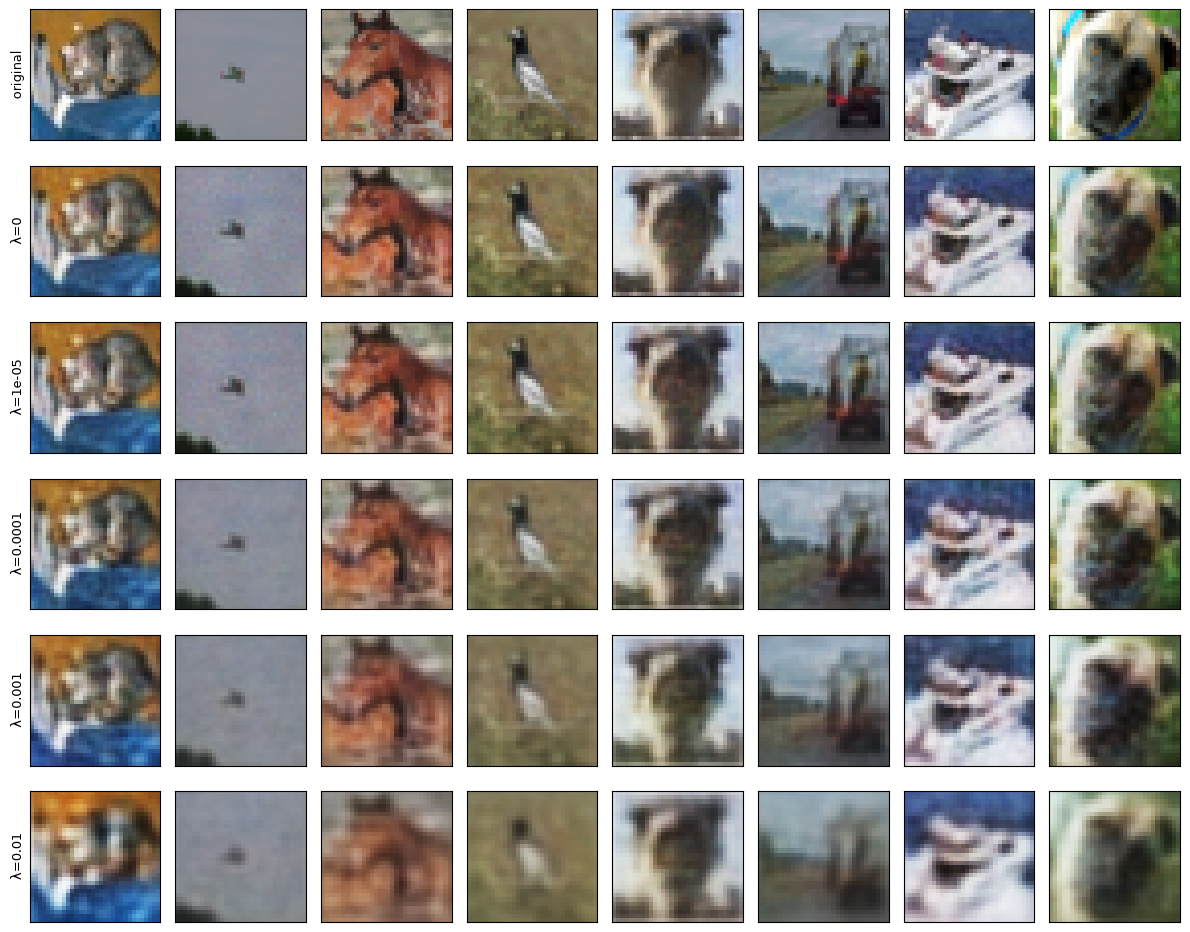

In [11]:
labels = [f'{r["lam"]:g}' for r in results]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].bar(labels, [r['mse'] for r in results]); axes[0].set_title('Test MSE (lower = better)')
axes[1].bar(labels, [r['mean_act'] for r in results]); axes[1].axhline(0.05, color='r', ls='--', label='ρ = 0.05')
axes[1].set_title('Mean hidden activation'); axes[1].legend()
axes[2].bar(labels, [r['active'] for r in results]); axes[2].set_title('% activations > 0.1')
for ax in axes: ax.set_xlabel('λ')
plt.tight_layout(); plt.show()

# Same 8 test images reconstructed by each model
idx8 = idx[:8]
fig, axes = plt.subplots(len(lambdas) + 1, 8, figsize=(12, 1.6 * (len(lambdas) + 1)))
for k, i in enumerate(idx8):
    axes[0, k].imshow(to_img(X_test[i]))
    for row, lam in enumerate(lambdas, start=1):
        with torch.no_grad():
            axes[row, k].imshow(to_img(sweep_models[lam](X_test_d[i:i+1])[1][0]))
for row, name in enumerate(['original'] + [f'λ={l:g}' for l in lambdas]):
    axes[row, 0].set_ylabel(name, fontsize=9)
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 8. Observations

- Training is stable; test MSE settles at about **0.0101** (PSNR ≈ 26 dB).
- Train and test loss are close, so the model is not overfitting.
- Reconstructions keep colours and overall shape but are **blurry**; fine details are lost.
- Most hidden activations are near zero with a few large ones, so the code is sparse.
- **Higher λ → sparser code but worse reconstruction:**
  - λ = 0: 98% of units active, MSE 0.0086
  - λ = 1e-2: 12% of units active, MSE 0.0244
- λ = 1e-5 is too small to make a difference; 1e-4 to 1e-3 gives a good balance.
- No neurons died at any λ.

---
# Self-learning extensions

- A. Visualizing learned features
- B. Comparison with PCA
- C. Linear-probe classification on the learned features
- D. Per-class error and noise test

## A. Learned features (encoder weights as images)

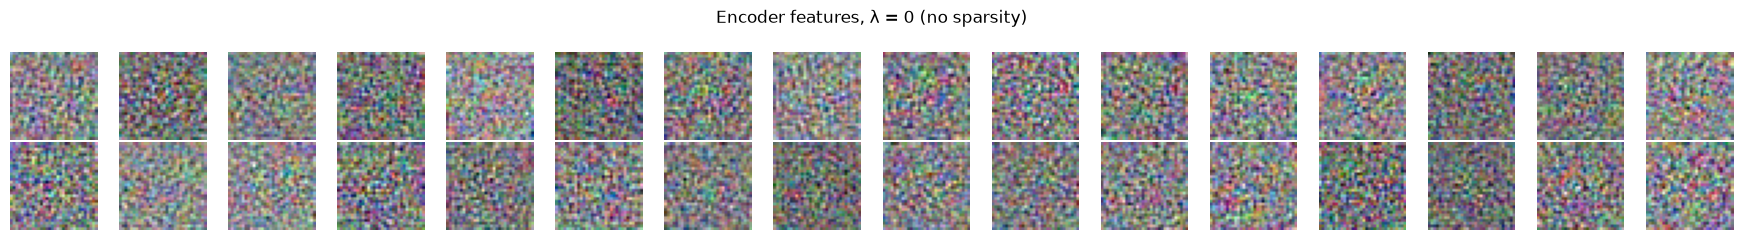

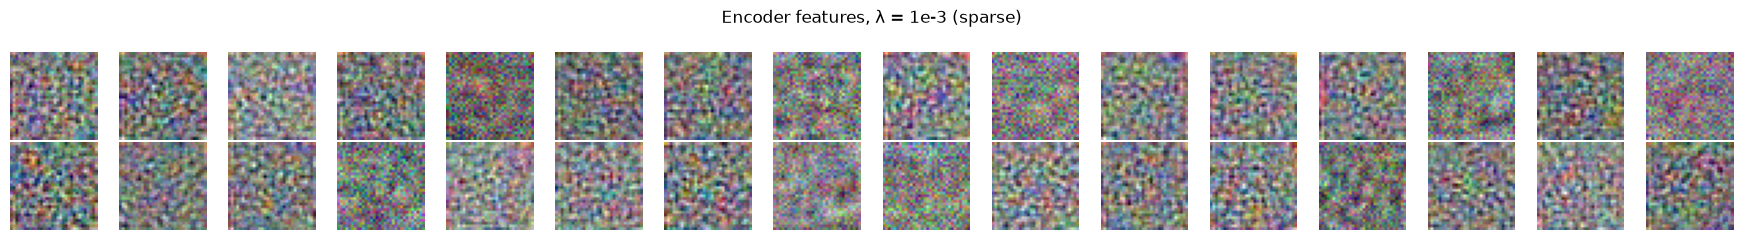

In [12]:
def show_features(m, title, n=32):
    W = m.encoder[0].weight.detach().cpu()[:n]               # (n, 3072)
    W = (W - W.amin(1, keepdim=True)) / (W.amax(1, keepdim=True) - W.amin(1, keepdim=True))
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 0.55, 2.4))
    for w, ax in zip(W, axes.flat):
        ax.imshow(w.view(3, 32, 32).permute(1, 2, 0).numpy()); ax.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_features(sweep_models[0], 'Encoder features, λ = 0 (no sparsity)')
show_features(sweep_models[1e-3], 'Encoder features, λ = 1e-3 (sparse)')

## B. Comparison with PCA

PCA k=  64: test MSE 0.0336 | PSNR 20.76 dB
PCA k= 256: test MSE 0.0105 | PSNR 25.82 dB
PCA k=1024: test MSE 0.0009 | PSNR 36.28 dB
Sparse AE (1024, λ=1e-4): test MSE 0.0101 | PSNR 25.99 dB


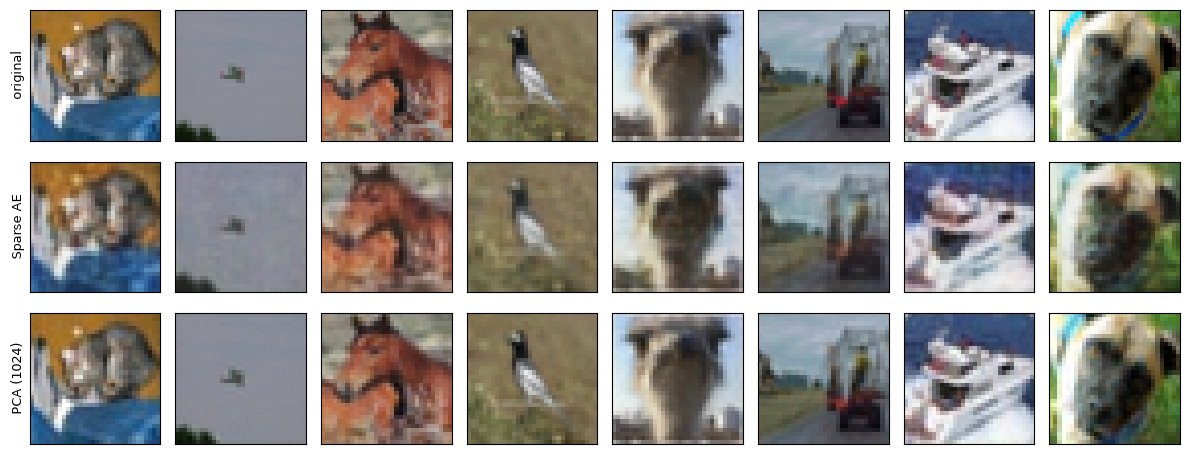

In [13]:
mean = X_train_d.mean(0)
_, _, V = torch.pca_lowrank(X_train_d - mean, q=1024, center=False)

pca_rows = []
for k in [64, 256, 1024]:
    Vk = V[:, :k]
    recon_pca = ((X_test_d - mean) @ Vk) @ Vk.T + mean
    pca_mse = F.mse_loss(recon_pca, X_test_d).item()
    pca_rows.append((k, pca_mse))
    print(f'PCA k={k:4d}: test MSE {pca_mse:.4f} | PSNR {psnr(pca_mse):.2f} dB')
print(f'Sparse AE (1024, λ=1e-4): test MSE {test_mse:.4f} | PSNR {psnr(test_mse):.2f} dB')

fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
V1024 = V[:, :1024]
for k, i in enumerate(idx8):
    with torch.no_grad():
        ae = model(X_test_d[i:i+1])[1][0]
    pc = ((X_test_d[i] - mean) @ V1024) @ V1024.T + mean
    for row, img in enumerate([X_test_d[i], ae, pc]):
        axes[row, k].imshow(to_img(img)); axes[row, k].set_xticks([]); axes[row, k].set_yticks([])
for row, name in enumerate(['original', 'Sparse AE', 'PCA (1024)']):
    axes[row, 0].set_ylabel(name, fontsize=9)
plt.tight_layout(); plt.show()

## C. Linear probe: classifying with the learned features

raw pixels    : 36.55% test accuracy
AE λ=0        : 41.24% test accuracy
AE λ=1e-05    : 42.82% test accuracy
AE λ=0.0001   : 45.82% test accuracy
AE λ=0.001    : 44.74% test accuracy
AE λ=0.01     : 46.70% test accuracy


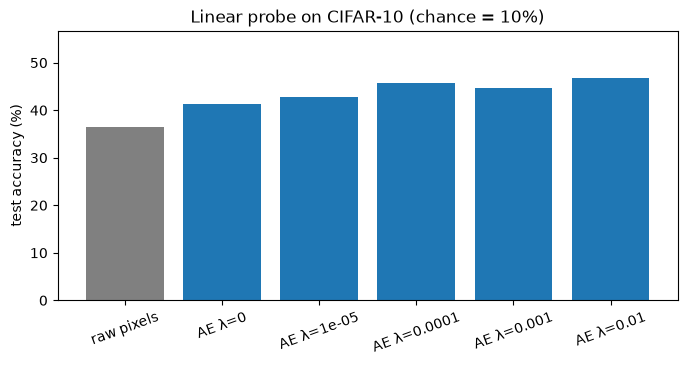

In [14]:
def linear_probe(F_train, F_test, epochs=30):
    # Softmax regression on fixed features; returns test accuracy (%)
    torch.manual_seed(0)
    mu, sd = F_train.mean(0), F_train.std(0) + 1e-6           # standardize features
    F_train, F_test = (F_train - mu) / sd, (F_test - mu) / sd
    clf = nn.Linear(F_train.shape[1], 10).to(device)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3, weight_decay=1e-4)
    ytr, yte = y_train.to(device), y_test.to(device)
    for _ in range(epochs):
        for b in torch.randperm(len(F_train), device=device).split(256):
            loss = F.cross_entropy(clf(F_train[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (clf(F_test).argmax(1) == yte).float().mean().item() * 100

probe = {'raw pixels': linear_probe(X_train_d, X_test_d)}
for lam in lambdas:
    m = sweep_models[lam]
    probe[f'AE λ={lam:g}'] = linear_probe(evaluate(m, X_train_d)[2], evaluate(m, X_test_d)[2])
for name, acc in probe.items():
    print(f'{name:14s}: {acc:.2f}% test accuracy')

plt.figure(figsize=(8, 3.5))
plt.bar(list(probe), list(probe.values()), color=['grey'] + ['C0'] * len(lambdas))
plt.ylabel('test accuracy (%)'); plt.title('Linear probe on CIFAR-10 (chance = 10%)')
plt.xticks(rotation=20); plt.ylim(0, max(probe.values()) + 10); plt.show()

## D. Per-class error and noise test

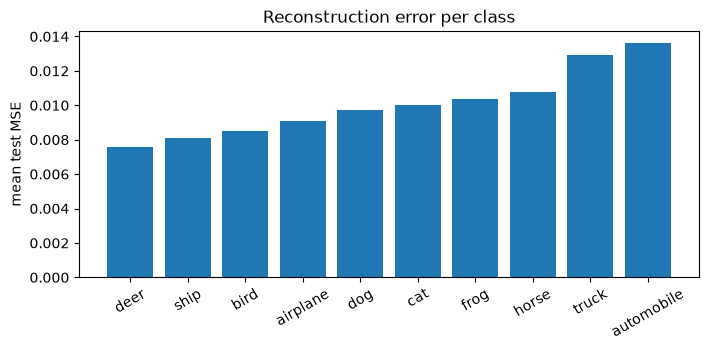

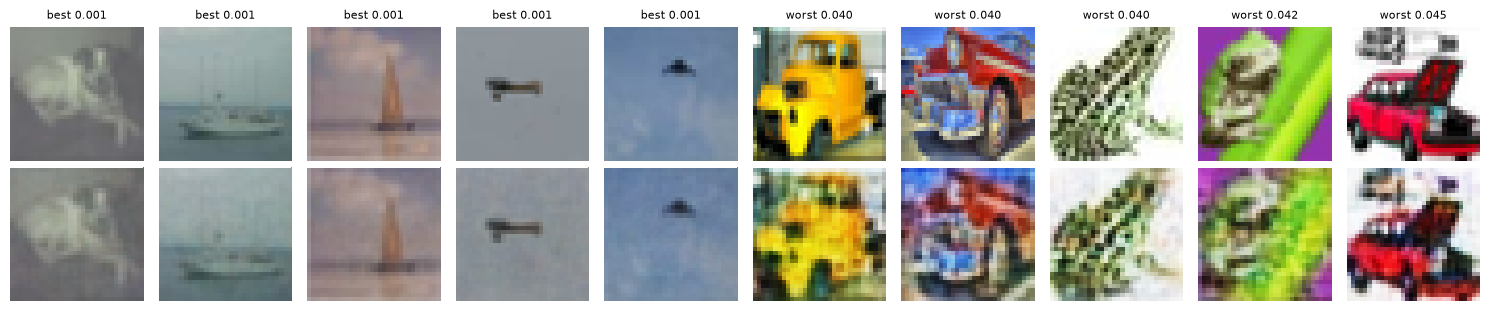

In [15]:
with torch.no_grad():
    per_img = ((model(X_test_d)[1] - X_test_d) ** 2).mean(1).cpu()
cls_err = [per_img[y_test == c].mean().item() for c in range(10)]
order = np.argsort(cls_err)
plt.figure(figsize=(8, 3.2))
plt.bar([CLASSES[c] for c in order], [cls_err[c] for c in order])
plt.ylabel('mean test MSE'); plt.title('Reconstruction error per class'); plt.xticks(rotation=30); plt.show()

# Best and worst reconstructed test images
best, worst = per_img.argsort()[:5], per_img.argsort()[-5:]
fig, axes = plt.subplots(2, 10, figsize=(15, 3.2))
for k, i in enumerate(torch.cat([best, worst])):
    with torch.no_grad():
        r = model(X_test_d[i:i+1])[1][0]
    axes[0, k].imshow(to_img(X_test[i])); axes[1, k].imshow(to_img(r))
    axes[0, k].set_title(('best ' if k < 5 else 'worst ') + f'{per_img[i]:.3f}', fontsize=8)
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.show()

noise σ | MSE(noisy, clean) | MSE(AE output, clean)
  0.1   |      0.0097       |       0.0123
  0.2   |      0.0372       |       0.0190


  0.4   |      0.1332       |       0.0469


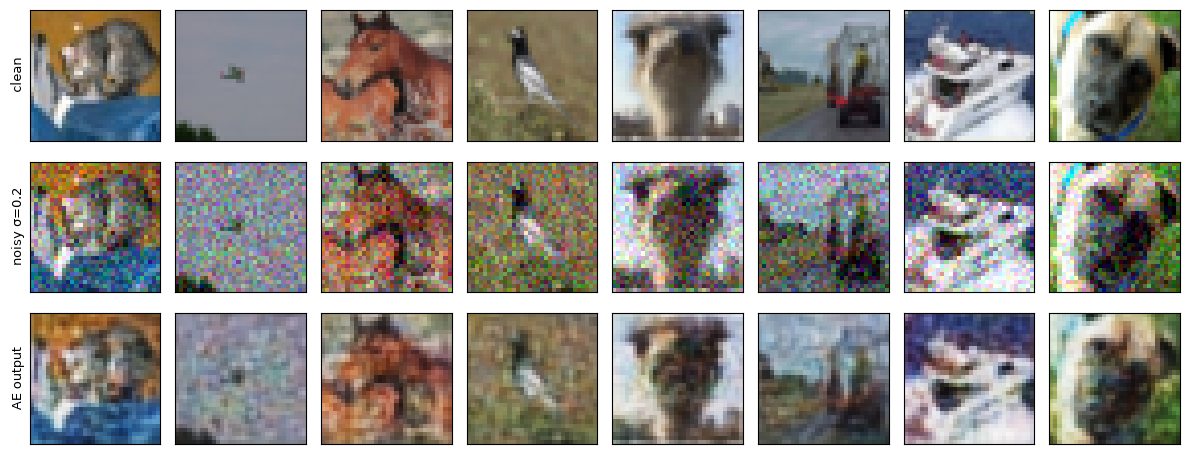

In [16]:
torch.manual_seed(0)
print('noise σ | MSE(noisy, clean) | MSE(AE output, clean)')
for sigma in [0.1, 0.2, 0.4]:
    noisy = (X_test_d + sigma * torch.randn_like(X_test_d)).clamp(-1, 1)
    with torch.no_grad():
        out = model(noisy)[1]
    print(f'  {sigma:.1f}   |      {F.mse_loss(noisy, X_test_d):.4f}       |       {F.mse_loss(out, X_test_d):.4f}')

noisy = (X_test_d[idx8] + 0.2 * torch.randn_like(X_test_d[idx8])).clamp(-1, 1)
with torch.no_grad():
    den = model(noisy)[1]
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for k in range(8):
    for row, img in enumerate([X_test_d[idx8[k]], noisy[k], den[k]]):
        axes[row, k].imshow(to_img(img)); axes[row, k].set_xticks([]); axes[row, k].set_yticks([])
for row, name in enumerate(['clean', 'noisy σ=0.2', 'AE output']):
    axes[row, 0].set_ylabel(name, fontsize=9)
plt.tight_layout(); plt.show()

## Self-learning observations

- **Features:** the weights look mostly noise-like, but the sparse model shows more structured patterns.
- **PCA:** reconstructs better at the same size (MSE 0.0009 vs 0.0101); the AE matches PCA with 256 components.
- **Linear probe:** all AE codes beat raw pixels (36.6%); sparser codes do best (up to 46.7%), even though they reconstruct worse.
- **Per-class:** smooth images (deer, ship) are easiest; cars and trucks are hardest.
- **Noise:** with moderate or heavy noise, the AE output is closer to the clean image than the noisy input.

## Conclusion

- The Sparse Autoencoder was adapted to CIFAR-10 and reconstructs images with a test MSE of about 0.01.
- λ trades reconstruction quality for sparsity.
- Sparse codes make better features for classification than raw pixels.